# Klasifikasi Sentimen Komentar KDMP dengan IndoBERT

**Soal No. 4:** Implementasi algoritma klasifikasi pada dataset pilihan menggunakan Python, evaluasi model, dan laporan analisis hasil.

- **Algoritma:** *Fine-tuning* IndoBERT (arsitektur Transformer/BERT berbahasa Indonesia) dengan Hugging Face
- **Dataset:** Komentar TikTok seputar Koperasi Merah Putih (KDMP), 3 kelas: `positif`, `negatif`, `netral`
- **Penanganan imbalance:** undersampling kelas `netral` + *weighted loss*
- **Perbaikan untuk komentar sarkas/ironis** (dari saran sebelumnya):
  1. **Emoji dipertahankan** dan diubah menjadi kata (mis. `😂` → `emoji tertawa`), karena pada komentar TikTok emoji sering menjadi penanda nada sindiran.
  2. **Kata tawa dan pola sindiran dipertahankan** (`wkwk`, `haha`, `katanya`, `padahal`, `ternyata`, dst.), lalu diberi penanda `sindiran` bila pola ditemukan.

> ⚠️ **Wajib GPU.** Jalankan di **Google Colab**: *Runtime → Change runtime type → T4 GPU*. Di CPU pelatihan bisa berjam-jam. Estimasi di T4: sekitar 3-6 menit per epoch.

## 1. Persiapan & Memuat Dataset

Dataset berisi komentar TikTok tentang **Koperasi Desa/Kelurahan Merah Putih (KDMP)** yang sudah diberi label sentimen (`positif`, `negatif`, `netral`).

> **Jika dijalankan di Google Colab:** upload file `KDMP_berlabel_perbaikan.csv` ke sesi Colab (panel kiri → Files), lalu ubah `DATA_PATH` bila perlu.

In [ ]:
import os, re, random, inspect, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import emoji
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)

from transformers import (AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
                          Trainer, TrainingArguments, EarlyStoppingCallback)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("PyTorch:", torch.__version__, "| GPU tersedia:", torch.cuda.is_available())
if not torch.cuda.is_available():
    print("PERINGATAN: GPU tidak terdeteksi. Pelatihan akan sangat lambat.")

PyTorch: 2.11.0+cu130 | GPU tersedia: True


## 2. Konfigurasi

| Parameter | Nilai | Keterangan |
|---|---|---|
| `MODEL_NAME` | `indolem/indobertweet-base-uncased` | IndoBERTweet: BERT berbahasa Indonesia yang dilatih dari teks **media sosial**, sehingga cocok untuk komentar informal dan emoji. Alternatif: `indobenchmark/indobert-base-p1` (IndoBERT dari teks formal). |
| `MAX_LEN` | 64 | Komentar umumnya pendek; emoji yang menjadi kata menambah beberapa token |
| `EPOCHS` | 3 | Fine-tuning BERT biasanya cukup 2-4 epoch |
| `LR` | 2e-5 | *Learning rate* standar untuk fine-tuning BERT |
| `SAMPLE_DEBUG` | `None` | Isi angka kecil (mis. `3000`) untuk uji coba cepat; kembalikan ke `None` untuk pelatihan penuh |

In [ ]:
MODEL_NAME = "indolem/indobertweet-base-uncased"   # alternatif: "indobenchmark/indobert-base-p1"
MAX_LEN = 64
EPOCHS = 3
BATCH_SIZE = 32
LR = 2e-5
SAMPLE_DEBUG = None
RUN_ABLATION = False   # True = latih juga model tanpa fitur emoji/tawa/sindiran sebagai pembanding (2x waktu)

In [ ]:
DATA_PATH = "KDMP_berlabel_perbaikan.csv"

df_raw = pd.read_csv(DATA_PATH)
print("Ukuran dataset awal :", df_raw.shape)
print("Kolom               :", list(df_raw.columns))
df_raw[["comment", "sentimen"]].head()

Ukuran dataset awal : (220051, 9)
Kolom               : ['video_id', 'comment_id', 'parent_comment_id', 'level', 'username', 'nickname', 'comment', 'create_time', 'sentimen']


,comment,sentimen
0,Beliau bilang untung nya 2 m ?,negatif
1,Makasih Mas,positif
2,Gimana untung nya 2 m..barang yg di jual ajh ga ada 1 m 😁,negatif
3,[Sticker] dibilang Makasih Mas udah 2M itu,positif
4,😳😳😳,netral


Missing value pada kolom penting:
comment     304
sentimen      0
dtype: int64 

Distribusi label awal:
sentimen
netral     144617
negatif     59206
positif     16228
Name: count, dtype: int64


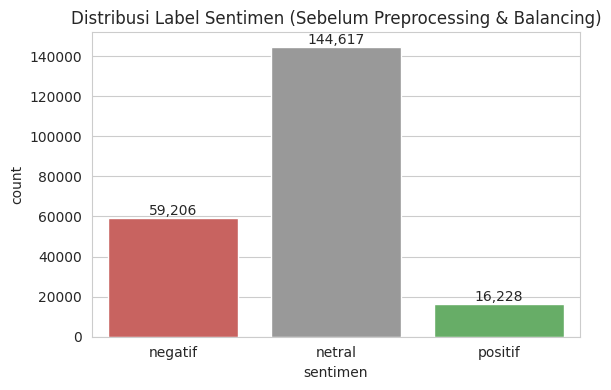

In [ ]:
print("Missing value pada kolom penting:")
print(df_raw[["comment", "sentimen"]].isna().sum(), "\n")
print("Distribusi label awal:")
print(df_raw["sentimen"].value_counts())

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df_raw, x="sentimen", order=["negatif", "netral", "positif"],
              palette=["#d9534f", "#999999", "#5cb85c"], ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Distribusi Label Sentimen (Sebelum Preprocessing & Balancing)")
plt.tight_layout(); plt.show()

## 3. Preprocessing Teks (dengan Penanganan Emoji, Tawa, dan Sindiran)

Berbeda dari notebook SVM/LSTM, preprocessing di sini **minimal** karena BERT sudah dilatih pada teks mentah:

1. Huruf kecil; hapus tag `[Sticker]`; URL → `httpurl`; mention → `@user` (format yang dipakai IndoBERTweet).
2. Huruf/tanda baca berulang dipadatkan (`mantaaaap` → `mantaap`, `????` → `??`).
3. **Saran 1, emoji → kata.** Emoji yang sering dipakai untuk sindiran dikelompokkan (mis. `😂🤣😹` → `emoji tertawa`, `😏🙄🗿` → `emoji sinis`); emoji lain diubah ke nama bahasa Indonesia lewat library `emoji`.
4. **Saran 2, kata tawa dan pola sindiran dipertahankan.** Variasi tawa disamakan (`wkwkwkwk`, `kwkwkw` → `wkwk`; `hahahaha` → `haha`). Bila ditemukan pola sindiran (`katanya`, `padahal`, `ternyata`, `mana ada`, `ya kali`, `emang bisa`, `sok`, atau kata puji + tawa seperti "mantap wkwk"), kata `sindiran` ditambahkan di akhir kalimat sebagai petunjuk eksplisit bagi model.
5. **Stopword tidak dibuang** dan angka tetap dipertahankan.
6. Hapus duplikat pada teks hasil bersih (menghindari *data leakage* antara data latih dan uji).

In [ ]:
# ---------- Saran 1: emoji -> kata ----------
EMOJI_GROUPS = {
    "tertawa":      "😂🤣😹😆",
    "senyum lebar": "😁😄😃😀😝😜🤪",
    "canggung":     "😅😳🥲",
    "sinis":        "😏🙄🗿🤭😌",
    "menangis":     "😭",
    "sedih":        "😢🥺😩😫😔🥹😞😿",
    "marah":        "😡🤬😠😤",
    "suka":         "👍🔥✅💪👏",
    "cinta":        "🥰❤😍😘💕💖",
    "doa":          "🙏🤲",
    "berpikir":     "🤔",
    "senyum":       "😊☺🙂😇",
}
EMOJI_MAP = {ch: name for name, chars in EMOJI_GROUPS.items() for ch in chars if ch != "\ufe0f"}
_MODIFIER = re.compile("[\U0001F3FB-\U0001F3FF\uFE0F\u200d]")   # warna kulit, variation selector, ZWJ

def _emoji_repl(e, data=None):
    key = _MODIFIER.sub("", e)
    name = EMOJI_MAP.get(key)
    if name is None:   # emoji lain -> nama dalam bahasa Indonesia
        name = emoji.demojize(key, language="id", delimiters=("", "")).replace("_", " ").strip()
        if not name or name == key:
            return " "
    return f" emoji {name} "

# ---------- Saran 2: tawa & pola sindiran ----------
def normalize_laughter(t):
    t = re.sub(r"\b[wk]{4,}\b", "wkwk", t)                 # wkwkwk, kwkwkw, wkkwwkkw ...
    t = re.sub(r"\b(?:ha){2,}h?\b", "haha", t)
    t = re.sub(r"\b(?:he){2,}h?\b", "hehe", t)
    t = re.sub(r"\b(?:xi){2,}x?\b", "xixi", t)
    t = re.sub(r"\bn?gakak\w*\b", "ngakak", t)
    return t

CUE_RE = re.compile(
    r"\b(katanya|padahal|ternyata|mana (ada|mungkin|bisa)|ya ?kali|(emang|memang) (bisa|boleh|ada)|(oh|owh) (ya|iya)|sok|pura pura)\b")
POS_WORD_RE = re.compile(r"\b(mantap|hebat|bagus|keren|pintar|pinter|top|wow|luar biasa)\b")
LAUGH_RE = re.compile(r"\b(wkwk|haha|hehe|xixi|ngakak)\b|emoji (tertawa|menangis|sinis|canggung|senyum lebar)")

def has_cue(t):
    return bool(CUE_RE.search(t)) or (bool(POS_WORD_RE.search(t)) and bool(LAUGH_RE.search(t)))

def clean_text(text, use_features=True):
    """use_features=True -> pipeline lengkap (emoji + tawa + sindiran). False -> pembanding tanpa fitur tsb."""
    t = str(text).lower()
    t = re.sub(r"\[[^\]]*\]", " ", t)                    # [Sticker], [Foto], dsb.
    t = re.sub(r"http\S+|www\.\S+", " httpurl ", t)
    t = re.sub(r"@\w+", " @user ", t)
    t = t.replace("\r", " ").replace("\n", " ")
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)                 # huruf/emoji/tanda baca berulang > 2
    if use_features:
        t = emoji.replace_emoji(t, replace=_emoji_repl)
        t = normalize_laughter(t)
    else:
        t = emoji.replace_emoji(t, replace=" ")
    t = re.sub(r"[^a-z0-9\s.,!?@']", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    if use_features and has_cue(t):
        t += " sindiran"
    return t

demo = ["Pak kamu di bohongi, mana ada gas elpiji 16rb 😂😅",
        "Mantap banget wkwkwkwkwk 🤣🤣🤣🤣",
        "katanya buat rakyat kecil, padahal malah mematikan warung 😭🙏🏻",
        "[Sticker] semoga sukses kopdes https://tiktok.com/xyz"]
for d in demo:
    print("ASLI :", d); print("BERSIH:", clean_text(d)); print()

ASLI : Pak kamu di bohongi, mana ada gas elpiji 16rb 😂😅
BERSIH: pak kamu di bohongi, mana ada gas elpiji 16rb emoji tertawa emoji canggung sindiran

ASLI : Mantap banget wkwkwkwkwk 🤣🤣🤣🤣
BERSIH: mantap banget wkwk emoji tertawa emoji tertawa sindiran

ASLI : katanya buat rakyat kecil, padahal malah mematikan warung 😭🙏🏻
BERSIH: katanya buat rakyat kecil, padahal malah mematikan warung emoji menangis emoji doa sindiran

ASLI : [Sticker] semoga sukses kopdes https://tiktok.com/xyz
BERSIH: semoga sukses kopdes httpurl



In [ ]:
df = df_raw.dropna(subset=["comment", "sentimen"]).copy()
df["text_full"]  = df["comment"].map(clean_text)                               # dengan emoji + tawa + sindiran
df["text_plain"] = df["comment"].map(lambda x: clean_text(x, use_features=False))  # pembanding (ablasi)

n0 = len(df)
df = df[df["text_full"].str.len() >= 3]
n1 = len(df)
df = df.drop_duplicates(subset="text_full", keep="first").reset_index(drop=True)
n2 = len(df)

# penanda untuk analisis (berdasarkan komentar asli)
df["f_emoji"] = df["comment"].map(lambda t: emoji.emoji_count(str(t)) > 0)
df["f_laugh"] = df["text_full"].map(lambda t: bool(re.search(r"\b(wkwk|haha|hehe|xixi|ngakak)\b", t)))
df["f_cue"]   = df["text_full"].map(lambda t: t.endswith(" sindiran"))

print(f"Setelah buang NaN         : {n0:,}")
print(f"Setelah buang teks kosong : {n1:,}")
print(f"Setelah buang duplikat    : {n2:,}")
print()
print(df["sentimen"].value_counts())

Setelah buang NaN         : 219,747
Setelah buang teks kosong : 216,356
Setelah buang duplikat    : 114,741

sentimen
netral     73095
negatif    32515
positif     9131
Name: count, dtype: int64


### 3.1 Bukti dari Data: Apakah Emoji, Tawa, dan Pola Sindiran Informatif?

Tabel berikut menunjukkan proporsi komentar yang memuat tiap penanda, dan sebaran sentimennya. Jika sebaran berbeda jauh dari data keseluruhan, penanda tersebut membawa informasi sentimen yang layak dipertahankan.

In [ ]:
rows = [{"kelompok": "Semua komentar", "jumlah": len(df), **df["sentimen"].value_counts(normalize=True).round(3).to_dict()}]
for col, nama in [("f_emoji", "Mengandung emoji"), ("f_laugh", "Mengandung tawa (wkwk/haha/...)"), ("f_cue", "Mengandung pola sindiran")]:
    sub = df[df[col]]
    rows.append({"kelompok": nama, "jumlah": len(sub), **sub["sentimen"].value_counts(normalize=True).round(3).to_dict()})
pd.DataFrame(rows).set_index("kelompok")

,jumlah,netral,negatif,positif
kelompok,,,,
Semua komentar,114741,0.637,0.283,0.080
Mengandung emoji,39699,0.696,0.240,0.064
Mengandung tawa (wkwk/haha/...),2885,0.612,0.342,0.045
Mengandung pola sindiran,3372,0.230,0.645,0.125


In [ ]:
# Emoji paling sering muncul beserta kecenderungan sentimennya
from collections import Counter
cnt = Counter()
per = {}
for t, s in zip(df["comment"], df["sentimen"]):
    for e in set(x["emoji"] for x in emoji.emoji_list(str(t))):
        cnt[e] += 1; per.setdefault(e, Counter())[s] += 1
top = pd.DataFrame([{"emoji": e, "jumlah": n, **{k: round(per[e][k] / n, 2) for k in ["negatif", "netral", "positif"]}}
                    for e, n in cnt.most_common(12)]).set_index("emoji")
top

,jumlah,negatif,netral,positif
emoji,,,,
😂,9054,0.25,0.69,0.06
😭,8928,0.21,0.75,0.03
🤣,5636,0.27,0.68,0.05
😁,3275,0.23,0.70,0.08
😅,2374,0.27,0.67,0.06
🗿,1851,0.23,0.72,0.05
🙏,1204,0.27,0.61,0.12
🥰,966,0.12,0.70,0.18
😳,857,0.29,0.65,0.06


## 4. Penyeimbangan Kelas (Undersampling Kelas Netral)

Kelas **netral** jauh lebih banyak dibanding kelas lain. Agar model tidak condong memprediksi "netral", jumlah data netral **dikurangi secara acak (random undersampling)** hingga sama dengan jumlah kelas terbanyak berikutnya (yaitu `negatif`).

Kelas `positif` tetap lebih sedikit, sehingga selain undersampling, pembobotan kelas (*class weight*) juga dipakai saat pelatihan (*weighted loss*).

Target jumlah kelas netral: 32,515

          sebelum  sesudah
sentimen                  
netral      73095    32515
negatif     32515    32515
positif      9131     9131


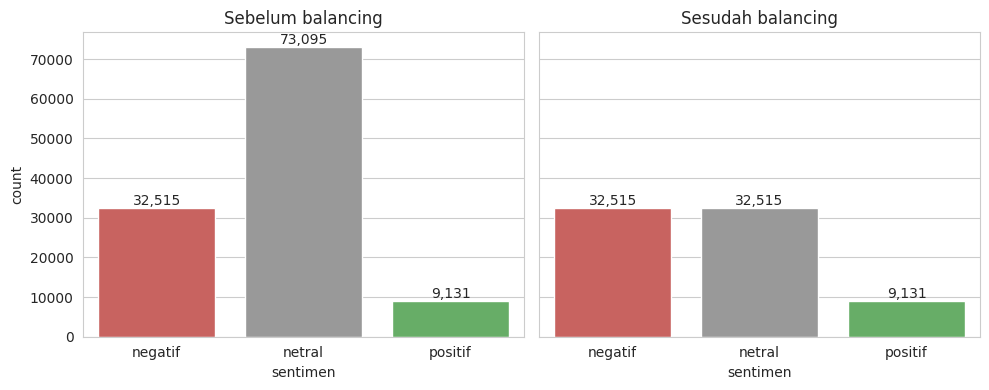

In [ ]:
SEED = 42
n_target = df[df["sentimen"] != "netral"]["sentimen"].value_counts().max()

df_netral = df[df["sentimen"] == "netral"].sample(n=min(n_target, (df["sentimen"] == "netral").sum()),
                                                   random_state=SEED)
df_bal = pd.concat([df[df["sentimen"] != "netral"], df_netral]).sample(frac=1, random_state=SEED).reset_index(drop=True)

print(f"Target jumlah kelas netral: {n_target:,}\n")
cmp = pd.DataFrame({"sebelum": df["sentimen"].value_counts(), "sesudah": df_bal["sentimen"].value_counts()})
print(cmp)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
order = ["negatif", "netral", "positif"]
colors = ["#d9534f", "#999999", "#5cb85c"]
for ax, d, ttl in zip(axes, [df, df_bal], ["Sebelum balancing", "Sesudah balancing"]):
    sns.countplot(data=d, x="sentimen", order=order, palette=colors, ax=ax)
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
    ax.set_title(ttl)
plt.tight_layout(); plt.show()

## 5. Pembagian Data (Train / Validation / Test)

Pembagian **70% latih : 15% validasi : 15% uji** (*stratified*). Validasi dipakai untuk memilih epoch terbaik, sedangkan data uji hanya dipakai di akhir.

In [ ]:
if SAMPLE_DEBUG:
    df_bal = df_bal.sample(SAMPLE_DEBUG, random_state=SEED).reset_index(drop=True)
    print(f"[DEBUG] hanya memakai {SAMPLE_DEBUG} data")

LABELS = ["negatif", "netral", "positif"]
le = LabelEncoder().fit(LABELS)
y_all = le.transform(df_bal["sentimen"])
idx = np.arange(len(df_bal))

tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=y_all, random_state=SEED)
va_idx, te_idx = train_test_split(tmp_idx, test_size=0.50, stratify=y_all[tmp_idx], random_state=SEED)

print(f"Train: {len(tr_idx):,} | Val: {len(va_idx):,} | Test: {len(te_idx):,}")
print("Distribusi train:", dict(zip(LABELS, np.bincount(y_all[tr_idx]))))

Train: 51,912 | Val: 11,124 | Test: 11,125
Distribusi train: {'negatif': np.int64(22760), 'netral': np.int64(22760), 'positif': np.int64(6392)}


## 6. Fungsi Pelatihan & Evaluasi

Satu fungsi `run_experiment` dipakai untuk melatih dan menguji model pada kolom teks tertentu (`text_full` atau `text_plain`), dengan pembagian data yang sama.

- **Tokenisasi** memakai *tokenizer* bawaan IndoBERT (WordPiece), padding dinamis per *batch* agar efisien.
- **Weighted loss**: bobot kelas membuat kesalahan pada kelas `positif` (lebih sedikit) dihukum lebih besar.
- **Seleksi model** berdasarkan *macro-F1* validasi, ditambah *early stopping*.

In [ ]:
class TextDS(torch.utils.data.Dataset):
    def __init__(self, enc, labels):
        self.enc, self.labels = enc, labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = int(self.labels[i])
        return item


class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        w = self.class_weights.to(outputs.logits.device)
        loss = torch.nn.functional.cross_entropy(outputs.logits, labels, weight=w)
        return (loss, outputs) if return_outputs else loss


def compute_metrics(p):
    logits = p.predictions[0] if isinstance(p.predictions, tuple) else p.predictions
    preds = logits.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, preds),
            "macro_f1": f1_score(p.label_ids, preds, average="macro")}


def run_experiment(text_col, tag):
    print(f"\n{'=' * 70}\nEksperimen: {tag}  (kolom teks: {text_col})\n{'=' * 70}")
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

    def make_ds(ids):
        enc = tokenizer(df_bal[text_col].iloc[ids].tolist(), truncation=True, max_length=MAX_LEN)
        return TextDS(enc, y_all[ids])

    tr_ds, va_ds, te_ds = make_ds(tr_idx), make_ds(va_idx), make_ds(te_idx)

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=3, ignore_mismatched_sizes=True,
        id2label={i: l for i, l in enumerate(le.classes_)}, label2id={l: i for i, l in enumerate(le.classes_)})

    cw = compute_class_weight("balanced", classes=np.arange(3), y=y_all[tr_idx])
    class_weights = torch.tensor(cw, dtype=torch.float)
    print("Class weight:", dict(zip(LABELS, cw.round(3))))

    ta_params = inspect.signature(TrainingArguments.__init__).parameters
    eval_key = "eval_strategy" if "eval_strategy" in ta_params else "evaluation_strategy"
    warm_key = "warmup_ratio" if "warmup_ratio" in ta_params else "warmup_steps"   # versi baru: float < 1 = rasio
    args = TrainingArguments(
        output_dir=f"out_{tag}", num_train_epochs=EPOCHS, learning_rate=LR,
        per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=BATCH_SIZE * 2,
        weight_decay=0.01, fp16=torch.cuda.is_available(),
        save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="macro_f1",
        greater_is_better=True, save_total_limit=1, logging_steps=50, report_to="none", seed=SEED,
        **{eval_key: "epoch", warm_key: 0.1})

    tr_params = inspect.signature(Trainer.__init__).parameters
    tok_key = "processing_class" if "processing_class" in tr_params else "tokenizer"
    trainer = WeightedTrainer(
        model=model, args=args, train_dataset=tr_ds, eval_dataset=va_ds,
        data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=1)],
        class_weights=class_weights, **{tok_key: tokenizer})

    trainer.train()

    out = trainer.predict(te_ds)
    logits = out.predictions[0] if isinstance(out.predictions, tuple) else out.predictions
    y_pred = logits.argmax(-1)
    y_true = y_all[te_idx]
    m = {"accuracy": accuracy_score(y_true, y_pred),
         "macro_precision": precision_score(y_true, y_pred, average="macro"),
         "macro_recall": recall_score(y_true, y_pred, average="macro"),
         "macro_f1": f1_score(y_true, y_pred, average="macro")}
    print({k: round(v, 4) for k, v in m.items()})
    return {"trainer": trainer, "model": trainer.model, "tokenizer": tokenizer,
            "y_true": y_true, "y_pred": y_pred, "proba": torch.softmax(torch.tensor(logits), -1).numpy(), "metrics": m}

## 7. Pelatihan Model IndoBERT (dengan Emoji, Tawa, dan Pola Sindiran)

In [ ]:
res = run_experiment("text_full", "indobert_full")


Eksperimen: indobert_full  (kolom teks: text_full)


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `2`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[trans

Class weight: {'negatif': np.float64(0.76), 'netral': np.float64(0.76), 'positif': np.float64(2.707)}


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.111990,0.101033,0.984538,0.980064
2,0.080382,0.071766,0.989932,0.986515
3,0.016076,0.071335,0.988763,0.984951


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'accuracy': 0.9892, 'macro_precision': 0.9856, 'macro_recall': 0.9841, 'macro_f1': 0.9849}


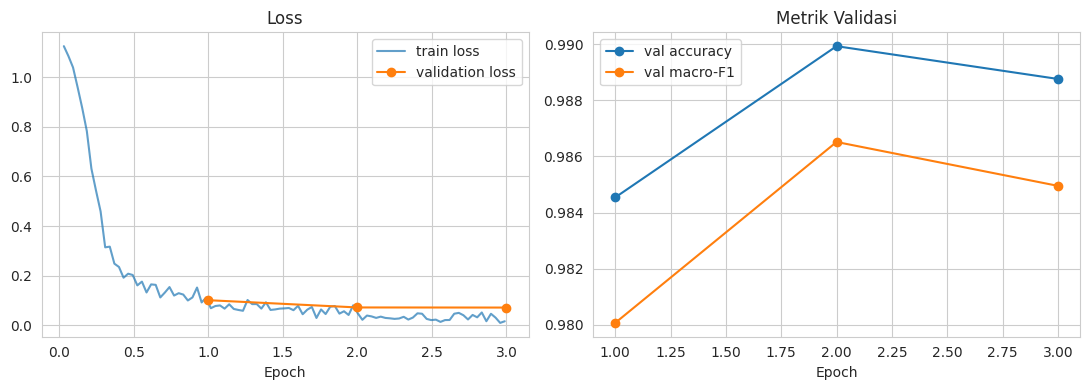

,epoch,eval_loss,eval_accuracy,eval_macro_f1
32,1.0,0.101033,0.984538,0.980064
65,2.0,0.071766,0.989932,0.986515
99,3.0,0.071335,0.988763,0.984951


In [ ]:
logs = pd.DataFrame(res["trainer"].state.log_history)
tr = logs[logs["loss"].notna()][["epoch", "loss"]]
ev = logs[logs["eval_loss"].notna()][["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1"]]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(tr["epoch"], tr["loss"], label="train loss", alpha=.7)
axes[0].plot(ev["epoch"], ev["eval_loss"], "o-", label="validation loss")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(ev["epoch"], ev["eval_accuracy"], "o-", label="val accuracy")
axes[1].plot(ev["epoch"], ev["eval_macro_f1"], "o-", label="val macro-F1")
axes[1].set_title("Metrik Validasi"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()
ev

## 8. Evaluasi pada Data Uji

Accuracy        : 0.9892
Macro Precision : 0.9856
Macro Recall    : 0.9841
Macro F1-score  : 0.9849
Weighted F1     : 0.9892

              precision    recall  f1-score   support

     negatif     0.9904    0.9893    0.9898      4878
      netral     0.9922    0.9951    0.9937      4878
     positif     0.9743    0.9679    0.9711      1369

    accuracy                         0.9892     11125
   macro avg     0.9856    0.9841    0.9849     11125
weighted avg     0.9892    0.9892    0.9892     11125



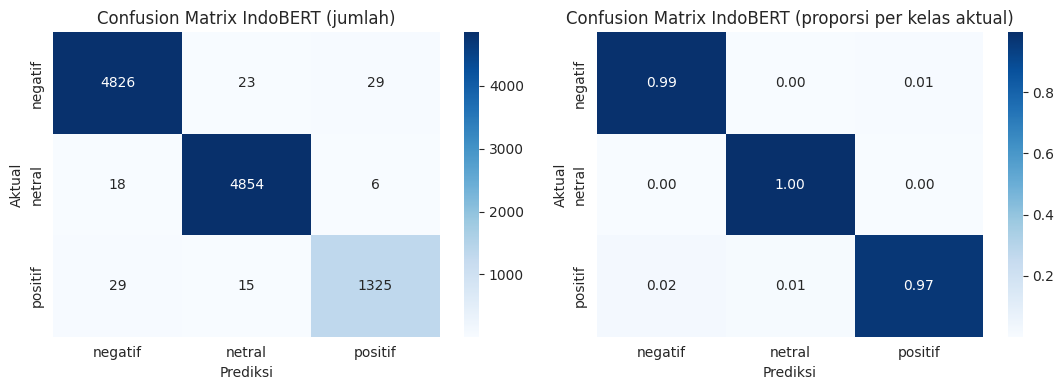

In [ ]:
def plot_cm(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_pct = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=axes[0])
    axes[0].set_title(f"{title} (jumlah)"); axes[0].set_xlabel("Prediksi"); axes[0].set_ylabel("Aktual")
    sns.heatmap(cm_pct, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=axes[1])
    axes[1].set_title(f"{title} (proporsi per kelas aktual)"); axes[1].set_xlabel("Prediksi"); axes[1].set_ylabel("Aktual")
    plt.tight_layout(); plt.show()

yt = le.inverse_transform(res["y_true"]); yp = le.inverse_transform(res["y_pred"])
print(f"Accuracy        : {accuracy_score(yt, yp):.4f}")
print(f"Macro Precision : {precision_score(yt, yp, average='macro'):.4f}")
print(f"Macro Recall    : {recall_score(yt, yp, average='macro'):.4f}")
print(f"Macro F1-score  : {f1_score(yt, yp, average='macro'):.4f}")
print(f"Weighted F1     : {f1_score(yt, yp, average='weighted'):.4f}\n")
print(classification_report(yt, yp, labels=LABELS, digits=4))
plot_cm(yt, yp, LABELS, "Confusion Matrix IndoBERT")

## 9. Analisis Khusus Komentar Sarkas / Beremoji

Apakah akurasi model berbeda pada komentar yang mengandung emoji, tawa, atau pola sindiran? Ini adalah evaluasi langsung terhadap kelemahan yang ingin diperbaiki.

In [ ]:
test_df = df_bal.iloc[te_idx].reset_index(drop=True).copy()
test_df["aktual"] = yt; test_df["prediksi"] = yp
test_df["benar"] = test_df["aktual"] == test_df["prediksi"]
test_df["confidence"] = res["proba"].max(axis=1).round(3)

rows = [{"kelompok": "Semua data uji", "jumlah": len(test_df), "akurasi": test_df["benar"].mean(),
         "macro_F1": f1_score(test_df["aktual"], test_df["prediksi"], average="macro")}]
for col, nama in [("f_emoji", "Mengandung emoji"), ("f_laugh", "Mengandung tawa"), ("f_cue", "Mengandung pola sindiran")]:
    for flag, lab in [(True, "ya"), (False, "tidak")]:
        s = test_df[test_df[col] == flag]
        if len(s) > 0:
            rows.append({"kelompok": f"{nama}: {lab}", "jumlah": len(s), "akurasi": s["benar"].mean(),
                         "macro_F1": f1_score(s["aktual"], s["prediksi"], average="macro")})
pd.DataFrame(rows).set_index("kelompok").round(4)

,jumlah,akurasi,macro_F1
kelompok,,,
Semua data uji,11125,0.9892,0.9849
Mengandung emoji: ya,3624,0.9876,0.9802
Mengandung emoji: tidak,7501,0.9900,0.9866
Mengandung tawa: ya,272,1.0000,1.0000
Mengandung tawa: tidak,10853,0.9889,0.9845
Mengandung pola sindiran: ya,434,0.9931,0.9882
Mengandung pola sindiran: tidak,10691,0.9891,0.9846


## 10. Analisis Kesalahan (Error Analysis)

In [ ]:
err = test_df[~test_df["benar"]]
print(f"Jumlah salah prediksi: {len(err):,} dari {len(test_df):,} ({len(err)/len(test_df):.1%})\n")
print(pd.crosstab(err["aktual"], err["prediksi"]))
pd.set_option("display.max_colwidth", 130)
print("\nSalah prediksi dengan confidence TINGGI (kandidat label yang perlu dicek ulang / sarkasme halus):")
err.sort_values("confidence", ascending=False)[["comment", "aktual", "prediksi", "confidence"]].head(12)

Jumlah salah prediksi: 120 dari 11,125 (1.1%)

prediksi  negatif  netral  positif
aktual                            
negatif         0      23       29
netral         18       0        6
positif        29      15        0

Salah prediksi dengan confidence TINGGI (kandidat label yang perlu dicek ulang / sarkasme halus):


,comment,aktual,prediksi,confidence
7472,loh piye to Iki nyugihno Indomaret,netral,negatif,1.000
2644,😣😣😣,netral,positif,0.999
5303,grafik e loo😭😭 @Bagus Akbar @nailafyuu,positif,netral,0.999
1976,"gatau kak, mau buat salad sama jus aja🙏🏻",netral,negatif,0.999
3179,[Sticker] Untung dari mana 20% 😂,negatif,positif,0.999
3452,heeh kerennn weh ck maneh nama🤣,negatif,positif,0.999
3784,Jawab lah masak ngilang sih 😁😁😁,negatif,netral,0.999
5024,rata2 komennya pada menjelekin negera. sekali2 kasilah dukungan kita lihat dlu perkembangan nya. baru komen. 😁,negatif,positif,0.999
3955,"Kami gamau beli soalnya kalau di ambil nnti raknya banyak bolong, kasian sm kalian yg nyusun jd hilang ke estetikannya😣",netral,positif,0.999
8508,Innalillahi 😭😭😭\r\nsudah bisa dipastikan KUD dpt teman ug sekian kesepian nn 🤣🤣🤣,negatif,netral,0.999


## 11. (Opsional) Ablasi: Dengan vs Tanpa Fitur Emoji, Tawa, dan Sindiran

Set `RUN_ABLATION = True` di bagian Konfigurasi, lalu jalankan ulang dari sel ini. Model dilatih ulang pada **data dan pembagian yang sama**, tetapi teksnya tanpa emoji, tanpa normalisasi tawa, dan tanpa penanda `sindiran`. Selisih skor menunjukkan kontribusi nyata saran 1 dan 2.

In [ ]:
if RUN_ABLATION:
    res_plain = run_experiment("text_plain", "indobert_plain")
    ab = pd.DataFrame({"Tanpa emoji/tawa/sindiran": res_plain["metrics"], "Dengan emoji/tawa/sindiran": res["metrics"]}).round(4)
    ab["selisih"] = (ab["Dengan emoji/tawa/sindiran"] - ab["Tanpa emoji/tawa/sindiran"]).round(4)
    display(ab)
else:
    print("Ablasi dilewati. Set RUN_ABLATION = True untuk menjalankannya.")

Ablasi dilewati. Set RUN_ABLATION = True untuk menjalankannya.


## 12. Perbandingan dengan SVM dan LSTM

In [ ]:
# Angka SVM & LSTM diambil dari notebook 01 dan 02 (data uji masing-masing).
# Catatan: pembagian data dan preprocessing berbeda (IndoBERT mempertahankan emoji, sehingga komentar yang
# hanya beda emoji tidak dianggap duplikat), jadi perbandingan ini bersifat indikatif, bukan head-to-head.
cmp = pd.DataFrame({
    "SVM (TF-IDF)": {"accuracy": 0.8545, "macro_f1": 0.8619},
    "LSTM":         {"accuracy": 0.8461, "macro_f1": 0.8519},
    "IndoBERT":     {"accuracy": res["metrics"]["accuracy"], "macro_f1": res["metrics"]["macro_f1"]},
}).round(4)
cmp

,SVM (TF-IDF),LSTM,IndoBERT
accuracy,0.8545,0.8461,0.9892
macro_f1,0.8619,0.8519,0.9849


## 13. Menyimpan Model & Contoh Prediksi

In [ ]:
SAVE_DIR = "model_indobert_sentimen_kdmp"
res["model"].save_pretrained(SAVE_DIR); res["tokenizer"].save_pretrained(SAVE_DIR)

def prediksi(kalimat_list):
    model, tok = res["model"], res["tokenizer"]
    model.eval()
    enc = tok([clean_text(k) for k in kalimat_list], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
    enc = {k: v.to(model.device) for k, v in enc.items()}
    with torch.no_grad():
        p = torch.softmax(model(**enc).logits, dim=-1).cpu().numpy()
    return [(le.classes_[i], float(p[j, i])) for j, i in enumerate(p.argmax(1))]

contoh = [
    "koperasi merah putih sangat membantu warga desa, semoga sukses",
    "cuma bikin boros anggaran negara, nanti juga bangkrut",
    "tokonya buka jam berapa ya",
    "katanya buat rakyat kecil, padahal malah mematikan warung 😂",
    "mantap banget programnya wkwkwk 🤣🤣",
]
for k, (lab, pr) in zip(contoh, prediksi(contoh)):
    print(f"[{lab:8s} {pr:.2f}] {k}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[positif  1.00] koperasi merah putih sangat membantu warga desa, semoga sukses
[negatif  1.00] cuma bikin boros anggaran negara, nanti juga bangkrut
[netral   1.00] tokonya buka jam berapa ya
[negatif  1.00] katanya buat rakyat kecil, padahal malah mematikan warung 😂
[positif  1.00] mantap banget programnya wkwkwk 🤣🤣


## 14. Kerangka Laporan Analisis

Setelah seluruh sel dijalankan, isi bagian berikut dengan angka dari output di atas.

**14.1 Ringkasan hasil**: tulis accuracy, macro-F1, dan epoch terbaik (bagian 7-8), serta jumlah data akhir setelah dedup dan balancing (bagian 3-5).

**14.2 Analisis per kelas**: lihat `classification_report` dan confusion matrix; kelas mana yang recall/presisinya terendah, dan kelas mana yang sering tertukar.

**14.3 Efek penanganan emoji, tawa, dan sindiran**
- Bagian 3.1: apakah sebaran sentimen pada komentar beremoji/bertawa/berpola sindiran berbeda dari data keseluruhan? (Pada data mentah, misalnya, semua komentar yang memuat kata `katanya` dan `padahal` berlabel negatif.)
- Bagian 9: apakah akurasi pada komentar beremoji/berpola sindiran lebih rendah, setara, atau lebih tinggi dibanding sisanya?
- Bagian 11 (jika dijalankan): berapa selisih macro-F1 dengan vs tanpa fitur?

**14.4 Perbandingan dengan SVM dan LSTM** (bagian 12): apakah IndoBERT lebih unggul, dan berapa besar selisihnya? Ingat bahwa pembagian data berbeda.

**14.5 Keterbatasan**: sarkasme halus tanpa penanda eksplisit tetap sulit; label bisa ambigu terutama negatif vs netral (cek salah prediksi ber-*confidence* tinggi di bagian 10); biaya komputasi tinggi dibanding SVM.

**14.6 Kesimpulan**: jawab apakah penanganan emoji/tawa/sindiran dan pemakaian IndoBERT memperbaiki kelemahan pada komentar sarkas, berdasarkan angka, bukan asumsi.

In [ ]:
import joblib

model = res["model"].to("cpu").eval()   # pindahkan ke CPU agar bisa dimuat di komputer tanpa GPU

paket = {
    "model": model,
    "tokenizer": res["tokenizer"],
    "labels": list(le.classes_),        # ['negatif', 'netral', 'positif']
    "max_len": MAX_LEN,
}
joblib.dump(paket, "indobert_sentimen_kdmp.joblib")

from google.colab import files
files.download("indobert_sentimen_kdmp.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>